In [1]:
import time, random, numpy as np, torch
import torch.nn as nn, torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import accuracy_score, f1_score
import matplotlib.pyplot as plt

# Reproductibilité
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print(torch.cuda.get_device_name(0))

Device: cuda
Tesla T4


In [2]:
import os
for root, _, files in os.walk("/kaggle/input"):
    for f in files: print(os.path.join(root, f))

/kaggle/input/datasets/hojjatk/mnist-dataset/t10k-images.idx3-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/t10k-labels.idx1-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/train-images.idx3-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/train-labels.idx1-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/t10k-images-idx3-ubyte/t10k-images-idx3-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/t10k-labels-idx1-ubyte/t10k-labels-idx1-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/train-images-idx3-ubyte/train-images-idx3-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/train-labels-idx1-ubyte/train-labels-idx1-ubyte


In [3]:
import struct

PATH = "/kaggle/input/datasets/hojjatk/mnist-dataset"   
def read_idx_images(path):
    with open(path, "rb") as f:
        magic, n, rows, cols = struct.unpack(">IIII", f.read(16))
        return np.frombuffer(f.read(), dtype=np.uint8).reshape(n, rows, cols)

def read_idx_labels(path):
    with open(path, "rb") as f:
        magic, n = struct.unpack(">II", f.read(8))
        return np.frombuffer(f.read(), dtype=np.uint8)

X_train = read_idx_images(f"{PATH}/train-images-idx3-ubyte/train-images-idx3-ubyte")
y_train = read_idx_labels(f"{PATH}/train-labels-idx1-ubyte/train-labels-idx1-ubyte")
X_test  = read_idx_images(f"{PATH}/t10k-images-idx3-ubyte/t10k-images-idx3-ubyte")
y_test  = read_idx_labels(f"{PATH}/t10k-labels-idx1-ubyte/t10k-labels-idx1-ubyte")
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(60000, 28, 28) (60000,) (10000, 28, 28) (10000,)


In [4]:
import json
import torch.nn.functional as F
from torchvision.models import vgg16, VGG16_Weights, alexnet, AlexNet_Weights
from sklearn.metrics import ConfusionMatrixDisplay

# Même découpage que Faster R-CNN
perm = torch.randperm(60000, generator=torch.Generator().manual_seed(SEED)).tolist()
train_idx, val_idx = perm[:54000][:15000], perm[54000:][:1000]

def to_t(X): return torch.from_numpy(X.copy()).float().div(255).unsqueeze(1)
def to_y(y): return torch.from_numpy(y.astype(np.int64))

Xtr, ytr = to_t(X_train[train_idx]).to(device), to_y(y_train[train_idx]).to(device)
Xva, yva = to_t(X_train[val_idx]).to(device),   to_y(y_train[val_idx]).to(device)
Xte, yte = to_t(X_test).to(device),             to_y(y_test).to(device)
print(Xtr.shape, Xva.shape, Xte.shape)

MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

def prep(x):   # (B,1,28,28) -> (B,3,64,64) normalisé ImageNet
    x = F.interpolate(x, size=(64, 64), mode="bilinear", align_corners=False)
    return (x.repeat(1, 3, 1, 1) - MEAN) / STD

torch.Size([15000, 1, 28, 28]) torch.Size([1000, 1, 28, 28]) torch.Size([10000, 1, 28, 28])


In [6]:
@torch.no_grad()
def evaluate(model, X, y, bs=256):
    model.eval(); tot, preds = 0.0, []
    for i in range(0, len(y), bs):
        xb, yb = prep(X[i:i+bs]), y[i:i+bs]
        with torch.autocast("cuda"):
            out = model(xb)
        tot += F.cross_entropy(out.float(), yb, reduction="sum").item()
        preds.append(out.argmax(1))
    preds, labels = torch.cat(preds).cpu().numpy(), y.cpu().numpy()
    return (tot / len(labels), accuracy_score(labels, preds),
            f1_score(labels, preds, average="macro"), preds, labels)

def finetune(name, model, epochs=3, lr=1e-4, bs=64):
    model = model.to(device)
    n_params = sum(p.numel() for p in model.parameters())
    print(f"{name} : {n_params:,} paramètres")
    opt = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    scaler = torch.amp.GradScaler("cuda")
    hist = {"train_loss": [], "val_loss": [], "val_acc": []}
    torch.cuda.synchronize(); t0 = time.time()
    for ep in range(epochs):
        model.train(); running = 0.0
        order = torch.randperm(len(ytr), device=device)
        for i in range(0, len(order), bs):
            idx = order[i:i+bs]
            xb, yb = prep(Xtr[idx]), ytr[idx]
            with torch.autocast("cuda"):
                loss = F.cross_entropy(model(xb), yb)
            opt.zero_grad(); scaler.scale(loss).backward()
            scaler.step(opt); scaler.update()
            running += loss.item() * len(idx)
        v_loss, v_acc, v_f1, _, _ = evaluate(model, Xva, yva)
        hist["train_loss"].append(running / len(ytr))
        hist["val_loss"].append(v_loss); hist["val_acc"].append(v_acc)
        print(f"Epoch {ep+1}/{epochs} | train loss {hist['train_loss'][-1]:.4f} | "
              f"val loss {v_loss:.4f} | val acc {v_acc:.4f} | val F1 {v_f1:.4f} | {time.time()-t0:.0f} s")
    torch.cuda.synchronize(); train_time = time.time() - t0

    t_loss, t_acc, t_f1, preds, labels = evaluate(model, Xte, yte)
    print(f"TEST {name} | loss {t_loss:.4f} | acc {t_acc:.4f} | F1 {t_f1:.4f} | temps {train_time:.1f} s")

    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1); plt.plot(hist["train_loss"], label="train"); plt.plot(hist["val_loss"], label="val")
    plt.title(f"{name} : loss"); plt.xlabel("Epoch"); plt.legend()
    plt.subplot(1, 2, 2); plt.plot(hist["val_acc"], marker="o")
    plt.title(f"{name} : accuracy (validation)"); plt.xlabel("Epoch")
    plt.tight_layout(); plt.savefig(f"{name.lower()}_curves.png", dpi=150); plt.show()
    ConfusionMatrixDisplay.from_predictions(labels, preds)
    plt.title(name); plt.savefig(f"{name.lower()}_confusion.png", dpi=150); plt.show()

    torch.save(model.state_dict(), f"{name.lower()}_mnist.pth")
    return {"accuracy": t_acc, "f1": t_f1, "loss": t_loss,
            "time_s": train_time, "params": n_params}

AlexNet : 57,044,810 paramètres
Epoch 1/3 | train loss 0.3103 | val loss 0.0812 | val acc 0.9720 | val F1 0.9715 | 8 s
Epoch 2/3 | train loss 0.0724 | val loss 0.0548 | val acc 0.9830 | val F1 0.9827 | 16 s
Epoch 3/3 | train loss 0.0433 | val loss 0.0447 | val acc 0.9850 | val F1 0.9852 | 24 s
TEST AlexNet | loss 0.0646 | acc 0.9819 | F1 0.9819 | temps 24.4 s


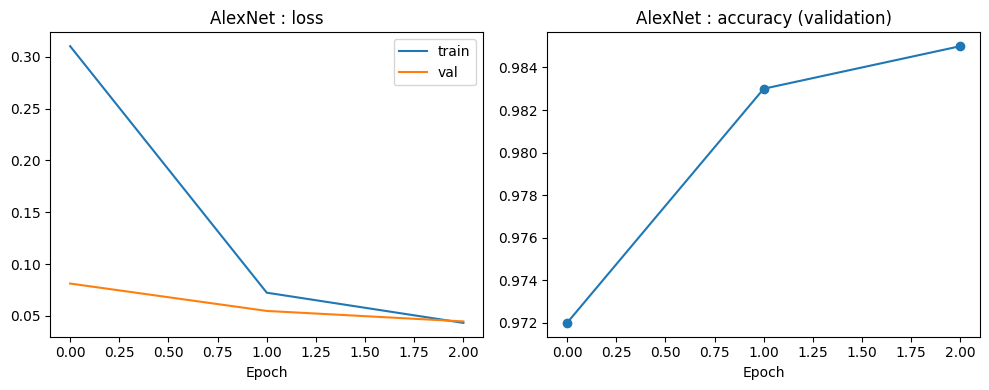

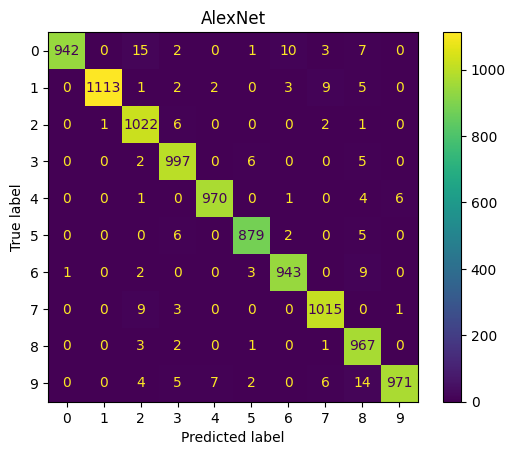

In [10]:
model = alexnet(weights=AlexNet_Weights.IMAGENET1K_V1)
model.classifier[6] = nn.Linear(4096, 10)          # 1000 classes -> 10
results = {}
results["AlexNet"] = finetune("AlexNet", model)
del model; torch.cuda.empty_cache()

VGG16 : 134,301,514 paramètres
Epoch 1/3 | train loss 0.2051 | val loss 0.0828 | val acc 0.9790 | val F1 0.9790 | 27 s
Epoch 2/3 | train loss 0.0489 | val loss 0.0963 | val acc 0.9750 | val F1 0.9754 | 53 s
Epoch 3/3 | train loss 0.0346 | val loss 0.0830 | val acc 0.9870 | val F1 0.9869 | 78 s
TEST VGG16 | loss 0.0425 | acc 0.9896 | F1 0.9896 | temps 77.7 s


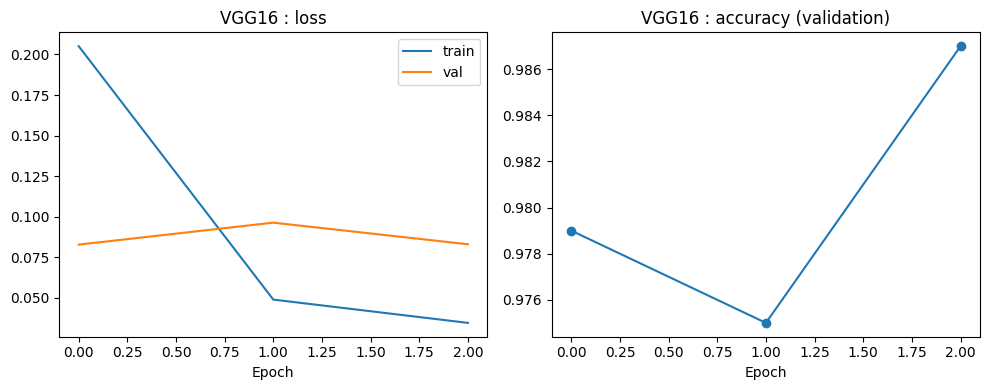

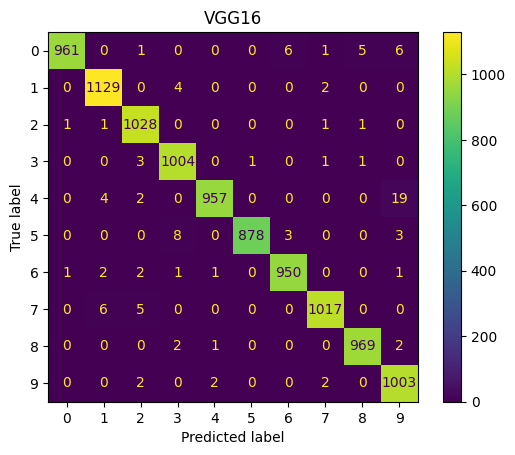

{'AlexNet': {'accuracy': 0.9819, 'f1': 0.9818628846484087, 'loss': 0.06458187703490258, 'time_s': 24.43344283103943, 'params': 57044810}, 'VGG16': {'accuracy': 0.9896, 'f1': 0.9896041521129867, 'loss': 0.042532825293391946, 'time_s': 77.69226956367493, 'params': 134301514}}


In [11]:
model = vgg16(weights=VGG16_Weights.IMAGENET1K_V1)
model.classifier[6] = nn.Linear(4096, 10)
results["VGG16"] = finetune("VGG16", model)
del model; torch.cuda.empty_cache()

json.dump(results, open("results_finetune.json", "w"), indent=2)
print(results)

               accuracy      f1    loss    time_s       params
CNN (scratch)    0.9904  0.9903  0.0289   22.6000     421834.0
Faster R-CNN     0.9818  0.9817  0.1250  395.4000   28329606.0
AlexNet (FT)     0.9819  0.9819  0.0646   24.4334   57044810.0
VGG16 (FT)       0.9896  0.9896  0.0425   77.6923  134301514.0


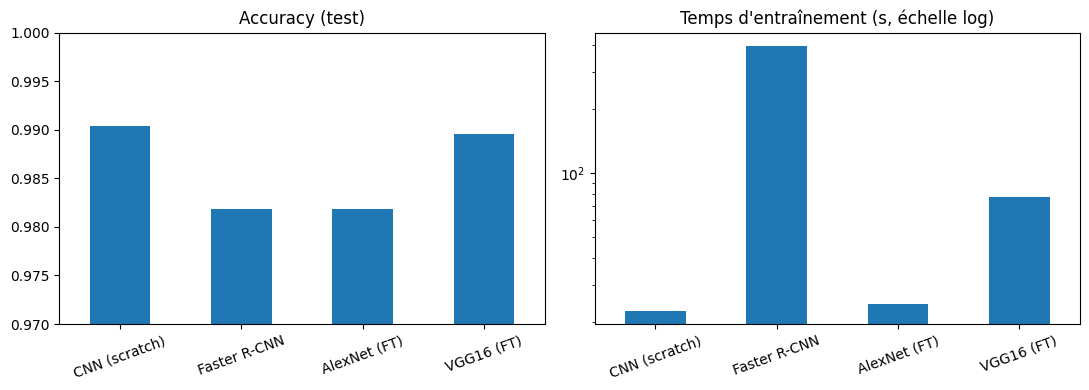

In [12]:
import pandas as pd
rows = {
 "CNN (scratch)":   {"accuracy": 0.9904, "f1": 0.9903, "loss": 0.0289, "time_s": 22.6,  "params": 421_834},
 "Faster R-CNN":    {"accuracy": 0.9818, "f1": 0.9817, "loss": 0.1250, "time_s": 395.4, "params": 28_329_606},
 "AlexNet (FT)":    results["AlexNet"],
 "VGG16 (FT)":      results["VGG16"],
}
df = pd.DataFrame(rows).T[["accuracy", "f1", "loss", "time_s", "params"]]
print(df.round(4).to_string())
df.to_csv("comparison_part1.csv")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df["accuracy"].plot.bar(ax=ax[0], ylim=(0.97, 1.0), title="Accuracy (test)", rot=20)
df["time_s"].plot.bar(ax=ax[1], logy=True, title="Temps d'entraînement (s, échelle log)", rot=20)
plt.tight_layout(); plt.savefig("comparison_part1.png", dpi=150); plt.show()